# Fontanka: fountain calling for a broad range of species

Fontanka was originally designed for fountain calling in zebrafish at 5.3 hpf (soon after ZGA), where other local Hi-C patterns like dots and stripes are not very pronounced. 

For other species and cell types, TADs and dots might be much more pronounced and significantly contaminate the fountain calling. 
In particular, dots and TAD centers might have yet high correlation with avergage fountain mask. 

With appropriate strategy of filtration and thresholding, we can filter out non-fountain features of Hi-C maps. 

In this example, I focus on fountain calling around ZGA of medaka fish from Nakamura et al. 2021. 

Zygotic genome activation (ZGA) in happens around 7 hpf for this species (stage 10.5, see Takashi 2004). 
This, we will use the stage 11, which is later than ZGA, as an example of fountain calling. 

- Nakamura, Ryohei, et al. "CTCF looping is established during gastrulation in medaka embryos." Genome Research 31.6 (2021): 968-980.\

- Iwamatsu, Takashi. "Stages of normal development in the medaka Oryzias latipes." Mechanisms of development 121.7-8 (2004): 605-618.


In [1]:
%load_ext autoreload
%autoreload 2

In [589]:
%%bash

# Pre-download the data:
mkdir -p data_medaka/cool/

wget https://osf.io/9qj27/download -O data_medaka/WT.avfountain.npy # Average fountain based on manually called ones
wget https://osf.io/6ygt9/download -O ./data_medaka/cool/HiC_st10.oryLat2.mapq_30.1000.mcool 
wget https://osf.io/cybf6/download -O data_medaka/oryLat2.arms.viewframe.tsv # Download chromosomal arms for oryLat

--2023-07-13 01:30:23--  https://osf.io/9qj27/download
Resolving osf.io (osf.io)... 35.190.84.173
Connecting to osf.io (osf.io)|35.190.84.173|:443... connected.
HTTP request sent, awaiting response... 302 FOUND
Location: https://files.osf.io/v1/resources/mt4vf/providers/osfstorage/64a84b44c3b67200e0d9085b?action=download&direct&version=1 [following]
--2023-07-13 01:30:23--  https://files.osf.io/v1/resources/mt4vf/providers/osfstorage/64a84b44c3b67200e0d9085b?action=download&direct&version=1
Resolving files.osf.io (files.osf.io)... 35.186.214.196
Connecting to files.osf.io (files.osf.io)|35.186.214.196|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13576 (13K) [application/octet-stream]
Saving to: ‘data_medaka/WT.avfountain.npy’

data_medaka/WT.avfo 100%[===================>]  13.26K  --.-KB/s    in 0.001s  

2023-07-13 01:30:23 (17.7 MB/s) - ‘data_medaka/WT.avfountain.npy’ saved [13576/13576]



In [2]:
# # Set up saving mode
do_save_figures = True
do_save_data = True

import os

output_folder = "./results_2025-12-02_AxG"
if not os.path.isdir(output_folder):
    os.mkdir(output_folder)

## 1. Prepare the genome

In [3]:
# obtain the chromosome lengths and positions of centromeres:
import bioframe
import cooler
import numpy as np
import pandas as pd

RESOLUTION = 5000
clr = cooler.Cooler(
    f"data_medaka/cool/HiC_st10.oryLat2.mapq_30.1000.mcool::/resolutions/{RESOLUTION}"
)

# Load pre-fetched chromosome arms (genomic viewframe):
arms = pd.read_csv(
    "data_medaka/oryLat2.arms.viewframe.tsv", sep="\t", header=None, index_col=None
)
arms.columns = ["chrom", "start", "end", "name"]
arms = bioframe.sort_bedframe(arms)

# # This is how I used to fetch chromosomes and arms, but it no longer works with bioframe/UCSC:
# chromsizes = bioframe.fetch_chromsizes('oryLat2', as_bed=True, provider="ucsc")
# chromnames = [x for x in clr.chromnames if x in chromsizes.chrom.values] # Should preserve the order of chromosomes in your cool-file
# cens = bioframe.fetch_centromeres('oryLat2', provider="ucsc")
# arms = bioframe.make_chromarms(chromsizes, cens, cols_chroms=chromsizes.columns)
# arms.start = arms.start.astype(int)
# arms.end = arms.end.astype(int)
# arms.loc[:, 'name'] = arms.apply(lambda x: f"{x.chrom}:{x.start}-{x.end}", axis=1)
# # Sort chromosome arms based on the cooler input:
# arms = bioframe.sort_bedframe(arms, chromsizes.set_index('chrom').loc[chromnames, :].reset_index())
# # Write the chromosome arms to the file (we need this to calculate appropriate expected per chromosome arm)
# arms.to_csv("data_medaka/oryLat2.arms.viewframe.tsv", sep="\t", header=None, index=None)

# Get and write genomic bins to the file:
bins = clr.bins()[:]
bins = (
    bioframe.overlap(bins, arms, how="left", return_index=True)
    .dropna(subset="start_")
    .drop_duplicates("index")
    .set_index("index")
)  # Clean up those bins that do not fall into selected chromosome arms
bins = bins[["chrom", "start", "end", "weight"]]
if do_save_data:
    bins.to_csv("./data_medaka/oryLat2-reduced.bins.tsv", sep="\t", index=True)

In [4]:
# We will use the annotation of clean and bad bins in the genome later.
# We define bad bins as those that were not corrected by iterative correction.

offset = 3 * RESOLUTION

bad_bins = bins.loc[np.isnan(bins.weight), :]
bad_bins = bioframe.expand(bad_bins, offset)
bad_bins = bioframe.trim(bad_bins, arms).dropna(subset="start")

clean_bins = bioframe.subtract(bins, bad_bins)[["chrom", "start", "end"]]

## 2. Call fountains

We will assume that fountains in medaka have similar shape and size as the ones observed in zebrafish. 
Thus,. we will re-use the mask obtained for zebrafish reference. If you know that in your samples the fountains are very different in size and shape, it's better to create fountain mask from scratch as described in `00_fountanka_zebrafish.ipynb`. 

Be careful with data resolution, as the mask itself is not linked to any particular resolution, it's a square matrix of 41x41 size. 
This size corresponds to square window of 400 Kb centered around the expected fountain base, but only at 10 Kb resolution.

In [ ]:
%%bash 

### Set up the outpu directory: 
mkdir -p ./data_medaka/expected/
mkdir -p ./data_medaka/snips/
mkdir -p ./data_medaka/fountains/

### Define the parameters:
NTHREADS=20
LABEL="HiC_st10"
RESOLUTION=5000
FLANK=100000
LABEL_REF="WT"
MASK_PATH="./data_medaka/${LABEL_REF}.avfountain.npy"

### Calculate expected:
cooltools expected-cis ./data_medaka/cool/${LABEL}.oryLat2.mapq_30.1000.mcool::resolutions/${RESOLUTION} \
    --regions ./data_medaka/oryLat2.arms.viewframe.tsv \
    -p $NTHREADS --clr-weight-name weight --ignore-diags 2 \
    -o ./data_medaka/expected/${LABEL}.expected.tsv

### Snip the genome:
fontanka slice-windows ./data_medaka/cool/${LABEL}.oryLat2.mapq_30.1000.mcool::resolutions/${RESOLUTION} \
    ./data_medaka/snips/${LABEL}.100Kb.snips.npy \
    -p $NTHREADS -W ${FLANK} \
    --view ./data_medaka/oryLat2.arms.viewframe.tsv --expected ./data_medaka/expected/${LABEL}.expected.tsv

### Call the fountains: 
fontanka apply-fountain-mask ./data_medaka/cool/${LABEL}.oryLat2.mapq_30.1000.mcool::resolutions/${RESOLUTION} \
        ./data_medaka/fountains/${LABEL}.fontanka.100Kb.ref.output.tsv \
        --snips ./data_medaka/snips/${LABEL}.100Kb.snips.npy \
        -W ${FLANK} -M ${MASK_PATH} \
        --view ./data_medaka/oryLat2.arms.viewframe.tsv

## 3. Visualize and filter fontanka output

In [5]:
import pandas as pd

exp = "HiC_st10"

# Read input table:
df_fountains = pd.read_table(
    f"./data_medaka/fountains/{exp}.fontanka.100Kb.ref.output.tsv", index_col=0
)  # Output table with fountains called by zebrafish reference

# Take only measurements for chromosomal arms:
columns = df_fountains.columns
df_fountains = (
    bioframe.overlap(df_fountains, arms).dropna(subset="start_").loc[:, columns]
)

# Clean up bad bins:
is_bad = bioframe.overlap(df_fountains, clean_bins)["start_"].isna().values
df_fountains.loc[is_bad, ["FS", "FS_peaks"]] = np.nan

In [6]:
df_fountains.sort_values("FS_peaks", ascending=False).dropna().head()

,chrom,start,end,window_start,window_end,FS,FS_peaks,Scharr_box
66829,chr10,24035000,24040000,23935000,24140000,0.645666,1.257582,12.226856
124117,chr21,12205000,12210000,12105000,12310000,0.500190,1.023302,60.198884
75152,chr11,9235000,9240000,9135000,9340000,0.502871,0.825854,41.788974
82984,chr7,18980000,18985000,18880000,19085000,0.436711,0.822023,11.048655
71983,chr22,22205000,22210000,22105000,22310000,0.295939,0.734636,26.922636


### 3.1. Threshold by peak prominence

In [7]:
# Apply thresholding to cut off huge peak in the distribution on the left:
from skimage.filters import threshold_li

peak_prominence_th = threshold_li(df_fountains.FS_peaks.values)
print(peak_prominence_th)

0.09054478785121764


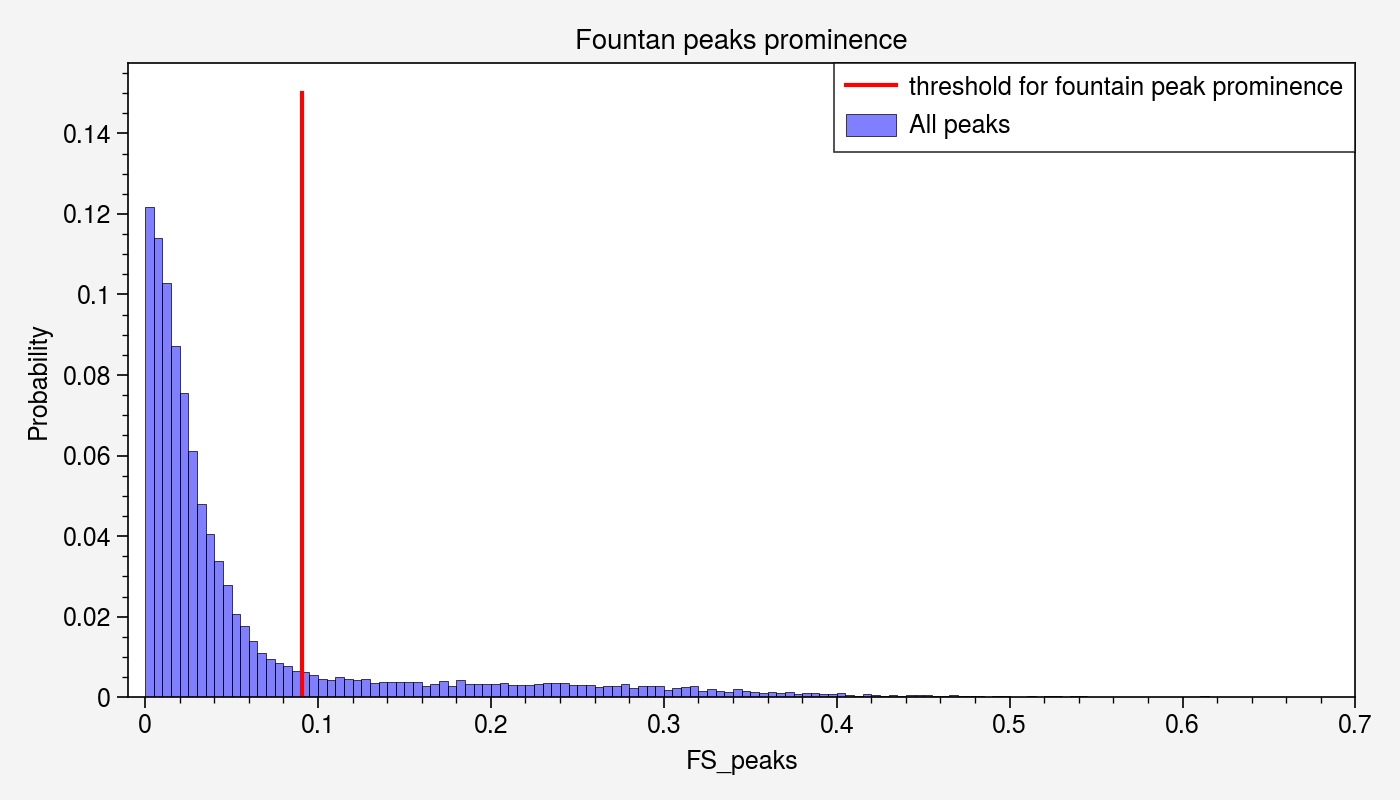

In [9]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Parameter for saving text as text and not vectorized objects:
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

import fontanka
import seaborn as sns

value = "FS_peaks"
title = "Fountan peaks prominence"

plt.figure(figsize=[7, 4])

sns.histplot(
    df_fountains.dropna(subset="FS_peaks")[value],
    color="blue",
    alpha=0.5,
    stat="probability",
    bins=np.arange(-0.01, 0.7, 0.005),
    label="All peaks",
)

plt.plot(
    [peak_prominence_th, peak_prominence_th],
    [0, 0.15],
    color="red",
    label="threshold for fountain peak prominence",
)

plt.xlim(-0.01, 0.7)

plt.title(title)
plt.legend()
plt.tight_layout()

In [10]:
df_fountains.loc[df_fountains["FS_peaks"] <= peak_prominence_th, "FS_peaks"] = np.nan

### 3.2 Threshold by noise score and fountain score

In [11]:
min_FS_ref = np.nanpercentile(df_fountains.FS, 90)
th_noise = np.nanpercentile(df_fountains.Scharr_box, 75)
df_strongest = df_fountains.query(f"FS>{min_FS_ref} and Scharr_box<{th_noise}").dropna(
    subset="FS_peaks"
)
df_strongest.sort_values("FS", ascending=False).dropna().head()

,chrom,start,end,window_start,window_end,FS,FS_peaks,Scharr_box
66829,chr10,24035000,24040000,23935000,24140000,0.645666,1.257582,12.226856
75152,chr11,9235000,9240000,9135000,9340000,0.502871,0.825854,41.788974
82984,chr7,18980000,18985000,18880000,19085000,0.436711,0.822023,11.048655
121993,chr21,1585000,1590000,1485000,1690000,0.430384,0.658830,23.276595
168815,chr3,35140000,35145000,35040000,35245000,0.405326,0.646468,38.775136


In [12]:
len(df_strongest)

1885

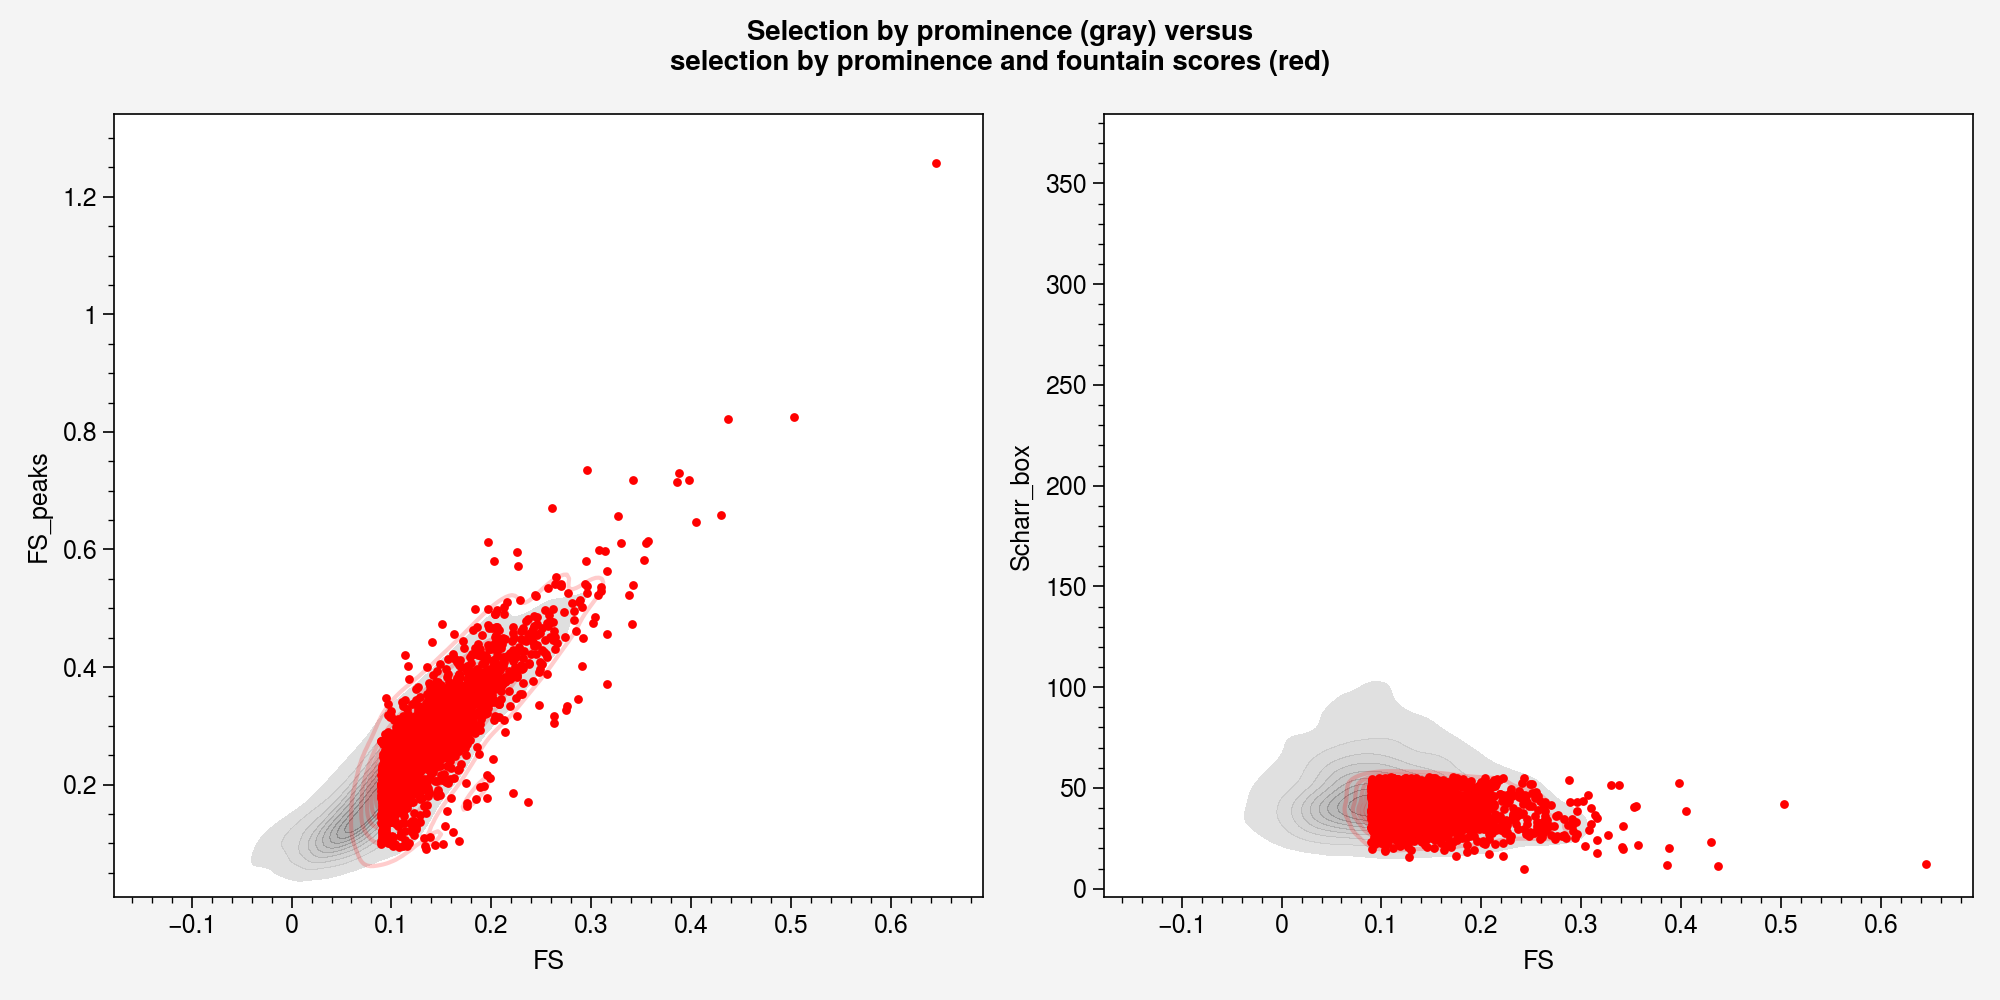

In [13]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=[10, 5])

ax = axes[0]
value_x = "FS"
value_y = "FS_peaks"

sns.kdeplot(
    data=df_fountains.dropna(subset="FS_peaks"),
    x=value_x,
    y=value_y,
    color="black",
    alpha=0.5,
    fill=True,
    ax=ax,
)
sns.scatterplot(
    data=df_strongest,
    x=value_x,
    y=value_y,
    color="red",
    alpha=1,
    s=10,
    linewidth=0,
    ax=ax,
)
sns.kdeplot(data=df_strongest, x=value_x, y=value_y, color="red", alpha=0.2, ax=ax)

ax = axes[1]
value_x = "FS"
value_y = "Scharr_box"

sns.kdeplot(
    data=df_fountains.dropna(subset="FS_peaks"),
    x=value_x,
    y=value_y,
    color="black",
    alpha=0.5,
    fill=True,
    ax=ax,
)
sns.scatterplot(
    data=df_strongest,
    x=value_x,
    y=value_y,
    color="red",
    alpha=1,
    s=10,
    linewidth=0,
    ax=ax,
)
sns.kdeplot(data=df_strongest, x=value_x, y=value_y, color="red", alpha=0.2, ax=ax)

fig.suptitle(
    "Selection by prominence (gray) versus\nselection by prominence and fountain scores (red)"
)
plt.tight_layout()

Visualize the resulting fountain and noise scores: 

In [14]:
# Functions to help with plotting
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import cm
import cooltools
import cooltools.lib.plotting
import bioframe

plt.rcParams["font.size"] = 12


def pcolormesh_45deg(ax, matrix_c, start=0, resolution=1, *args, **kwargs):
    start_pos_vector = [start + resolution * i for i in range(len(matrix_c) + 1)]
    import itertools

    n = matrix_c.shape[0]
    t = np.array([[1, 0.5], [-1, 0.5]])
    matrix_a = np.dot(
        np.array(
            [
                (i[1], i[0])
                for i in itertools.product(start_pos_vector[::-1], start_pos_vector)
            ]
        ),
        t,
    )
    x = matrix_a[:, 1].reshape(n + 1, n + 1)
    y = matrix_a[:, 0].reshape(n + 1, n + 1)
    im = ax.pcolormesh(x, y, np.flipud(matrix_c), *args, **kwargs)
    im.set_rasterized(True)
    return im


from matplotlib.ticker import EngFormatter

bp_formatter = EngFormatter("b")


def format_ticks(ax, x=True, y=True, rotate=True):
    if y:
        ax.yaxis.set_major_formatter(bp_formatter)
    if x:
        ax.xaxis.set_major_formatter(bp_formatter)
        ax.xaxis.tick_bottom()
    if rotate:
        ax.tick_params(axis="x", rotation=45)

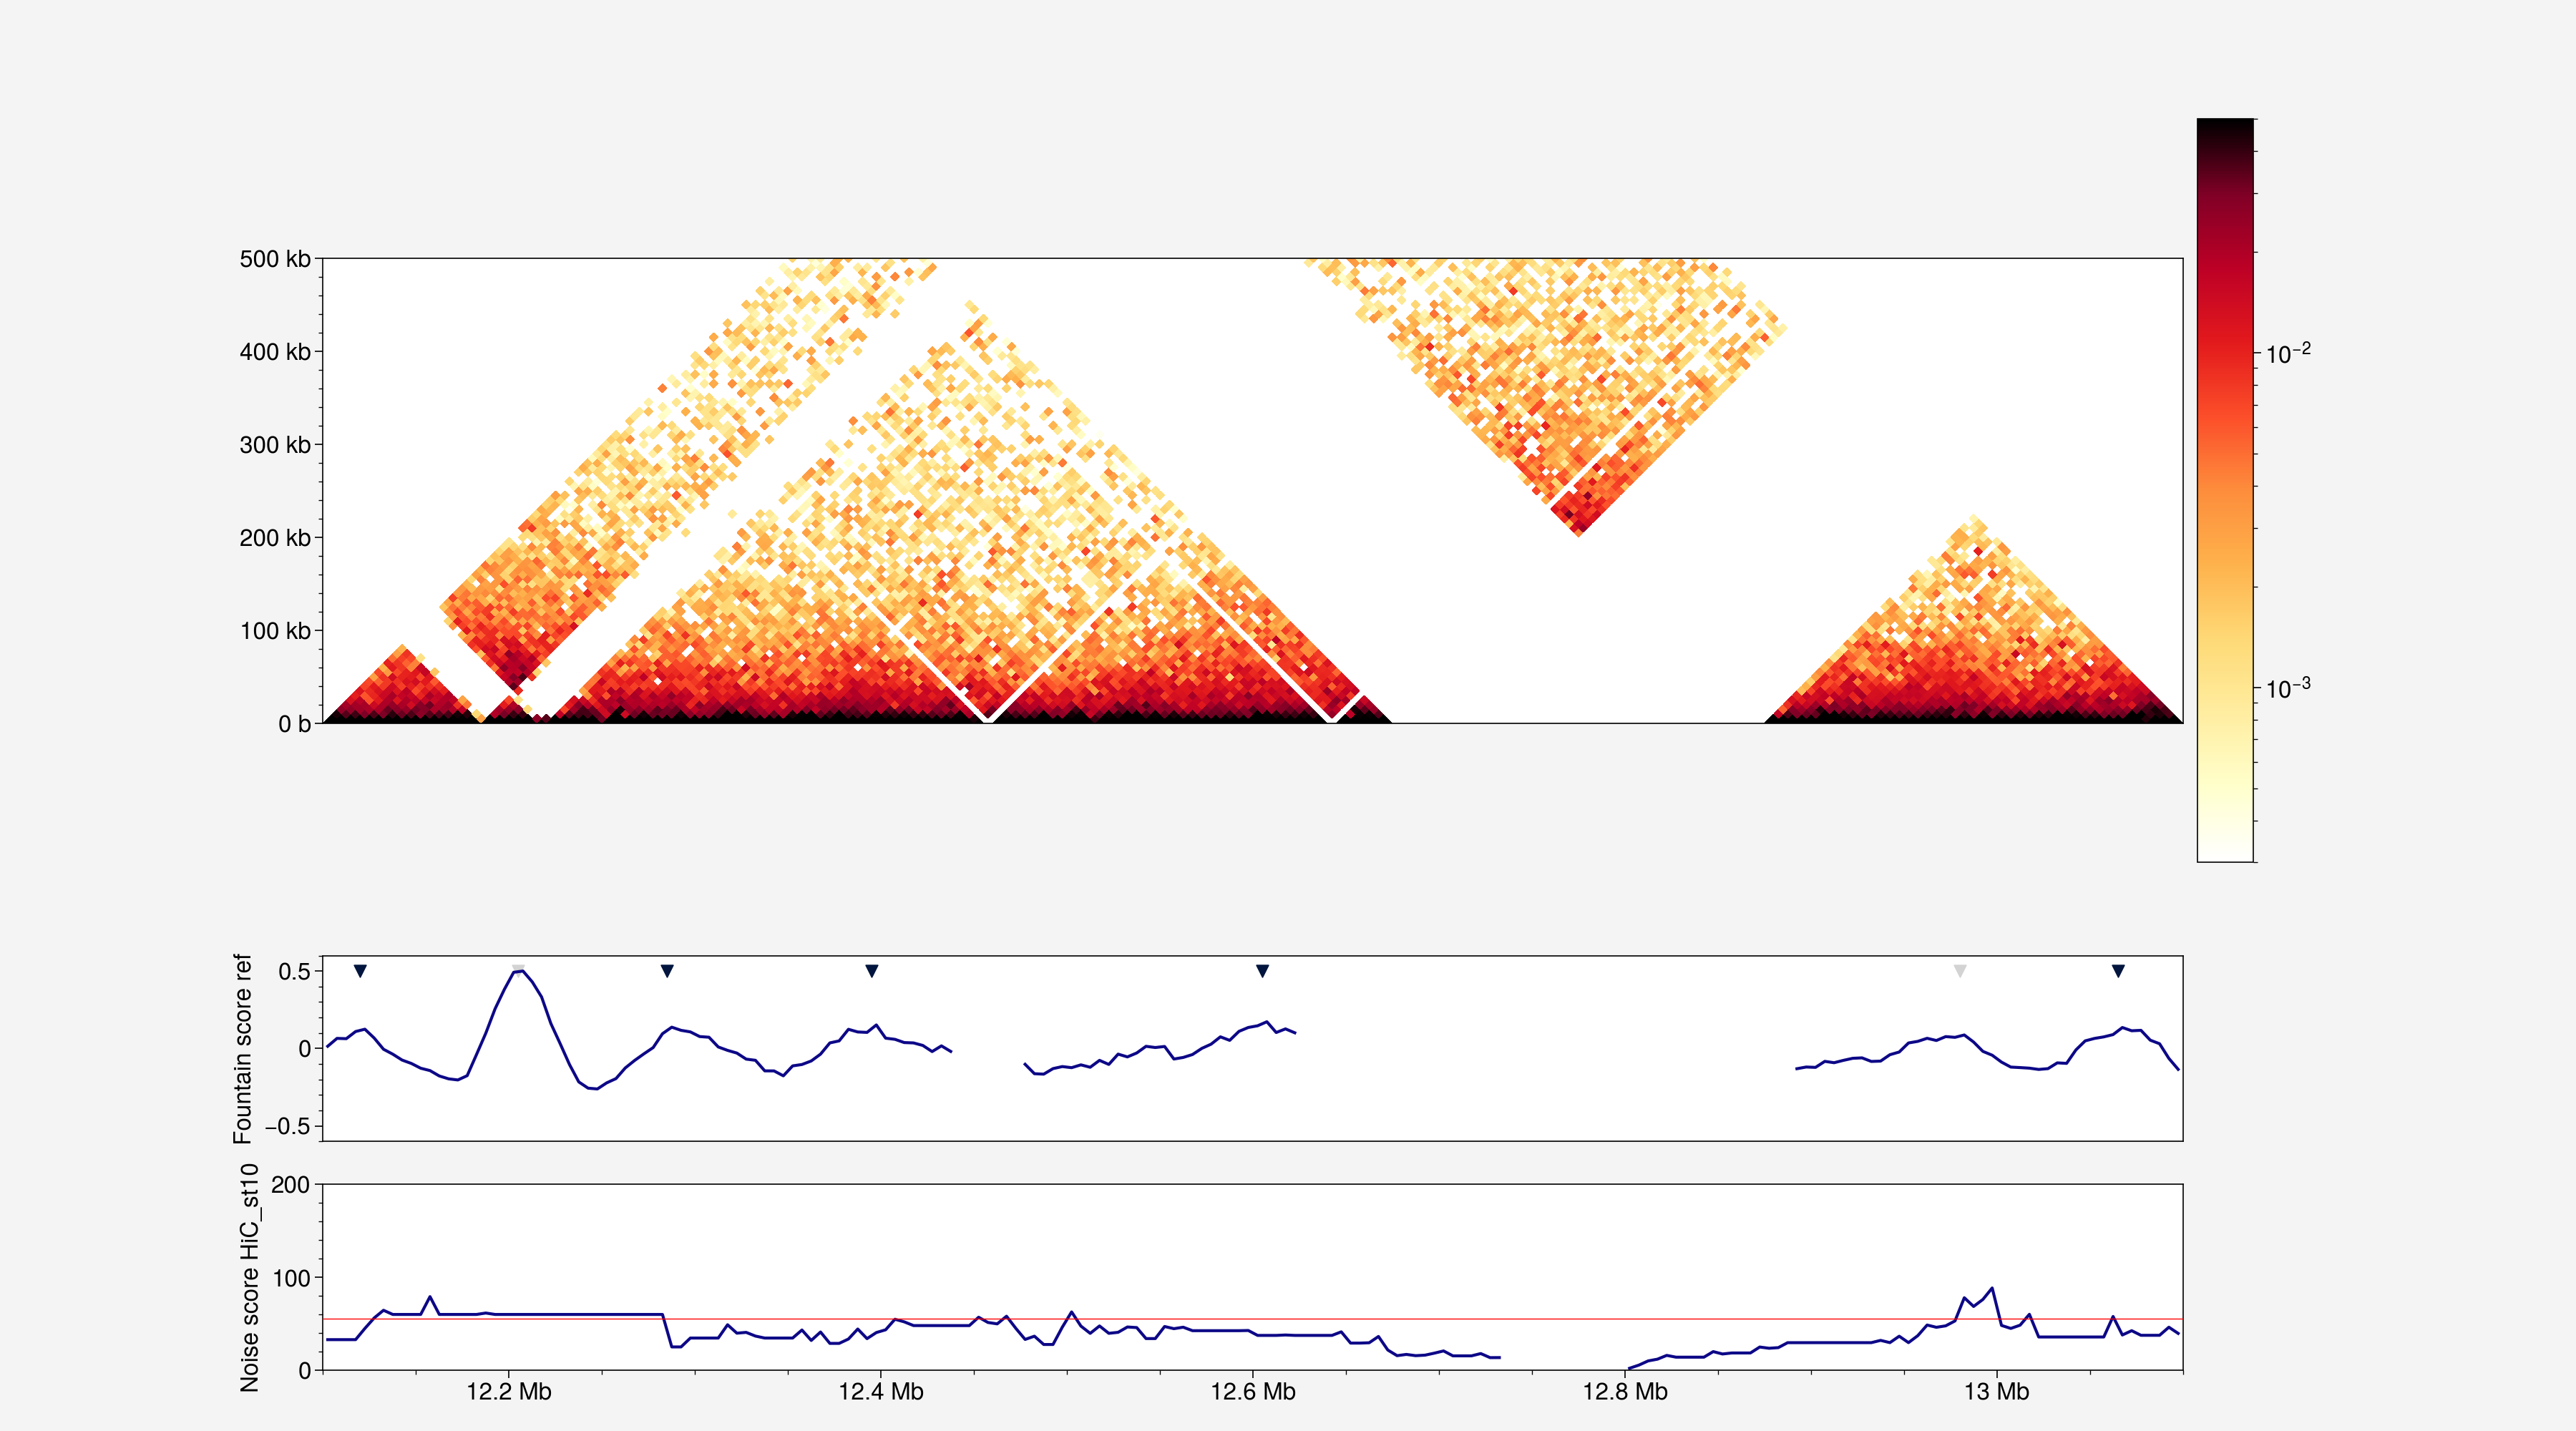

In [15]:
RESOLUTION = 5_000

start = 12100000
end = start + 200 * RESOLUTION
region = ("chr21", start, end)

norm = LogNorm(vmax=0.05, vmin=0.0003)
cmap = "fall"
data = clr.matrix(balance=True).fetch(region)

f, ax = plt.subplots(figsize=(18, 10))
im = pcolormesh_45deg(
    ax, data, start=region[1], resolution=RESOLUTION, norm=norm, cmap=cmap
)
ax.set_aspect(0.5)
ax.set_ylim(0, 100 * RESOLUTION)
format_ticks(ax, rotate=False)
ax.xaxis.set_visible(False)

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="3%", pad=0.1, aspect=6)
plt.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)


# Reference-based fountain score:
FS_region = bioframe.select(df_fountains, region)

FS_ax = divider.append_axes("bottom", size="20%", pad=0.0, sharex=ax)
FS_ax.set_prop_cycle(plt.cycler("color", plt.cm.plasma(np.linspace(0, 1, 5))))
FS_ax.plot(FS_region[["start", "end"]].mean(axis=1), FS_region["FS"])
FS_ax.set_ylabel(f"Fountain score ref")
FS_ax.set_ylim(-0.6, 0.6)
FS_ax.xaxis.set_visible(False)

FS_region_peaks = FS_region.dropna(subset="FS_peaks")
for i, r in FS_region_peaks.iterrows():
    FS_ax.scatter(
        x=r.start,
        y=0.5,
        marker="v",
        color="lightgray",
        label="All peaks in fountain score",
    )

# Strongest fountains
FS_region = bioframe.select(df_strongest, region)
FS_region_peaks = FS_region.dropna(subset="FS_peaks")
for i, r in FS_region_peaks.iterrows():
    FS_ax.scatter(
        x=r.start, y=0.5, marker="v", color="navy", label="Selected fountains"
    )


# Noise score:
FS_region = bioframe.select(df_fountains, region)
SS_ax = divider.append_axes("bottom", size="20%", pad=0.3, sharex=ax)
SS_ax.set_prop_cycle(plt.cycler("color", plt.cm.plasma(np.linspace(0, 1, 5))))
SS_ax.plot(FS_region[["start", "end"]].mean(axis=1), FS_region[f"Scharr_box"])
SS_ax.axhline(th_noise, color="red", lw=0.5, zorder=5)
SS_ax.set_ylabel(f"Noise score {exp}")
SS_ax.set_ylim(0, 200)
format_ticks(SS_ax, y=False, rotate=False)

ax.set_xlim(region[1], region[2])

f.tight_layout()

In [16]:
len(df_strongest)

1885

In [17]:
if do_save_data:
    df_strongest.sort_values("FS", ascending=False).to_csv(
        "data_medaka/strongest.score-sorted.st10.oryLat2.tsv", sep="\t"
    )
    df_strongest.to_csv(
        "data_medaka/strongest.genome-sorted.st10.oryLat2.tsv", sep="\t"
    )
    df_strongest.reset_index()[["chrom", "start", "end", "index"]].to_csv(
        "data_medaka/strongest.genome-sorted.st10.oryLat2.bed",
        sep="\t",
        header=False,
        index=False,
    )
    bioframe.expand(df_strongest, pad=20_000).reset_index()[
        ["chrom", "start", "end", "index"]
    ].to_csv(
        "data_medaka/strongest.genome-sorted.withoffset.st10.oryLat2.bed",
        sep="\t",
        header=False,
        index=False,
    )

### Visualization of average fountains and fountain instances

In [18]:
exp = "HiC_st10"
stack = np.load(f"./data_medaka/snips/{exp}.100Kb.snips.npy")

In [19]:
stack.shape

(41, 41, 177111)

In [20]:
plt.rcParams.update({"axes.grid": False})

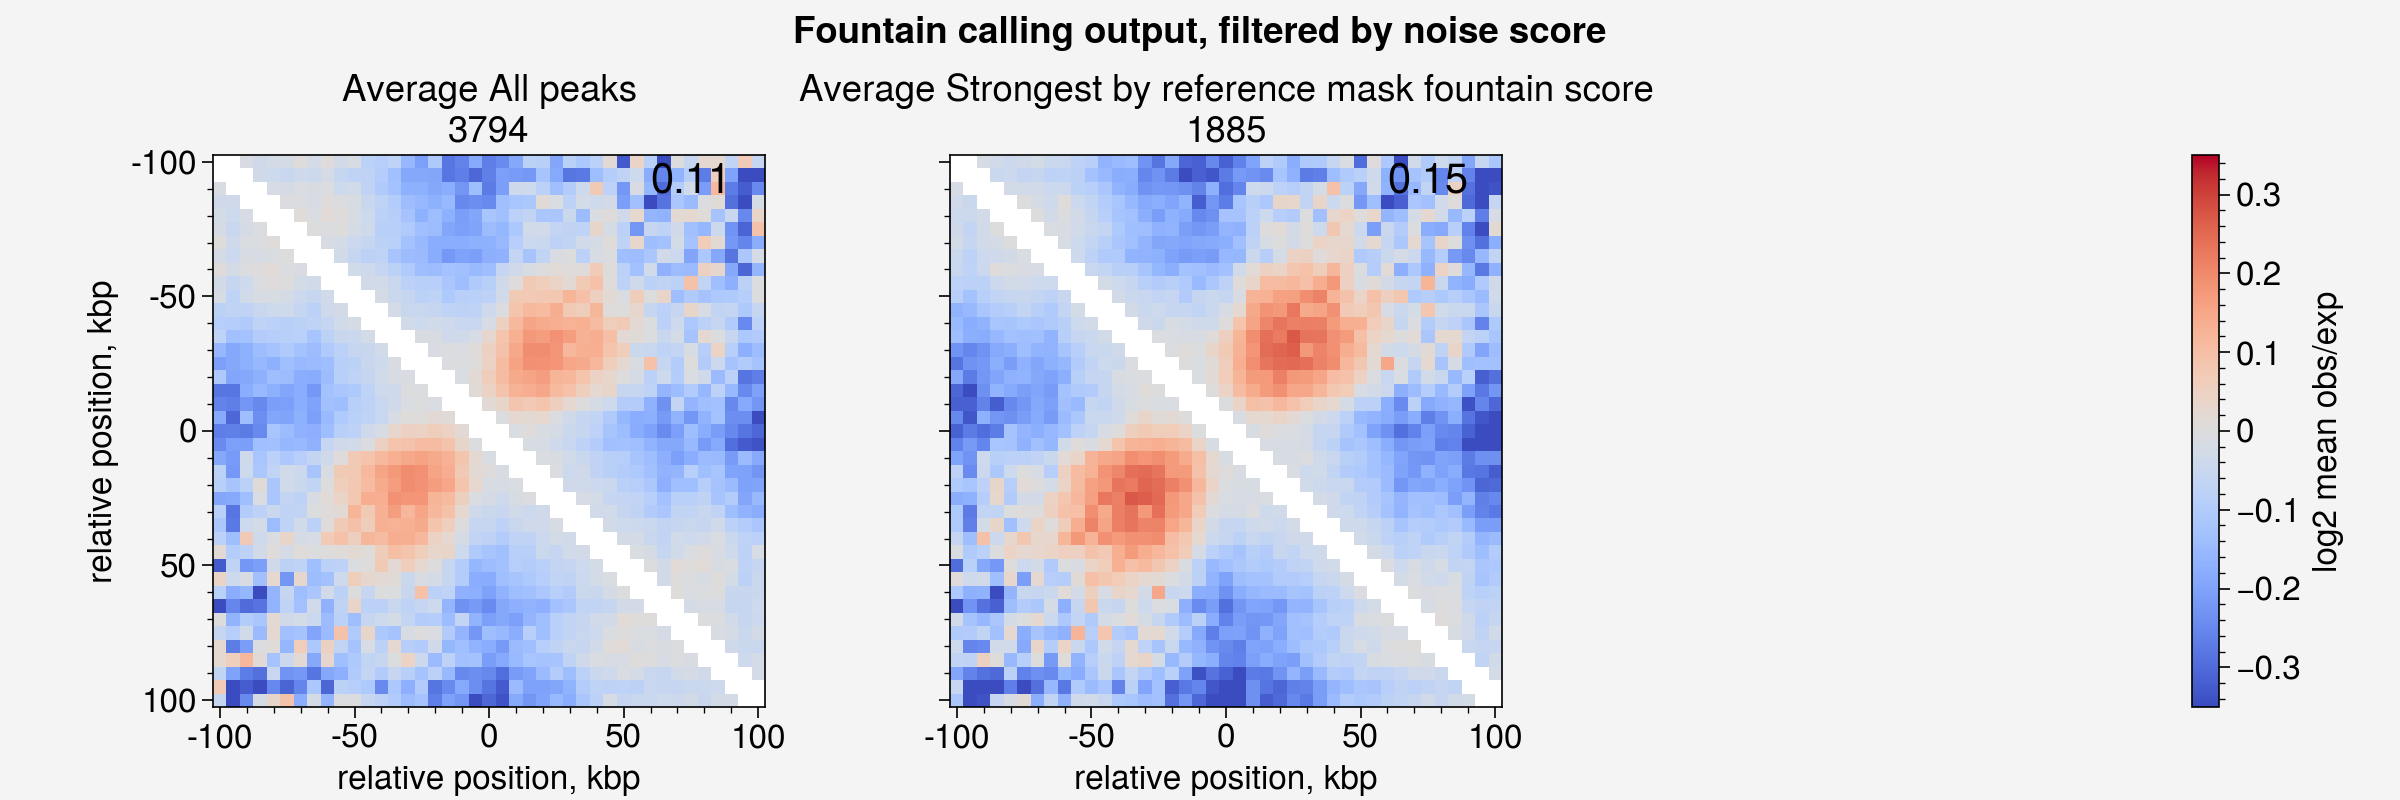

In [21]:
# Plot average patterns:
FLANK = 100_000

fig, axes = plt.subplots(1, 3, figsize=[12, 4], sharey=True, sharex=True)
axes.flatten()[-1].set_axis_off()

output = {}
for i, (df, title) in enumerate(
    [
        (df_fountains.dropna(subset="FS_peaks"), "All peaks"),
        (df_strongest, "Strongest by reference mask fountain score"),
    ]
):

    bins_fountains = (
        bioframe.overlap(bins, df, how="left", return_index=True)
        .dropna(subset=["chrom_"])
        .set_index("index")
    )
    index_fountains = list(bins_fountains.index.values)

    # Visualize fountain average:
    pile = np.nanmean(stack[:, :, index_fountains], axis=2)
    pile = fontanka.reflect(pile)

    ax = axes.flatten()[i]
    im = ax.imshow(
        np.log2(pile), vmax=0.35, vmin=-0.35, cmap="coolwarm", interpolation=None
    )

    ticks_pixels = np.linspace(0, FLANK * 2 // RESOLUTION, 5)
    ticks_kbp = ((ticks_pixels - ticks_pixels[-1] / 2) * RESOLUTION // 1000).astype(int)
    ax.set_xticks(ticks_pixels)
    ax.set_xticklabels(ticks_kbp)
    ax.set_xlabel("relative position, kbp")

    if i == 0:
        ax.set_yticks(ticks_pixels)
        ax.set_yticklabels(ticks_kbp)
        ax.set_ylabel("relative position, kbp")

    score = np.nanmean(df_fountains.loc[index_fountains, "FS"])
    ax.text(
        32.0,
        0.0,
        f"{score:.2f}",
        horizontalalignment="left",
        verticalalignment="top",
        fontsize=15,
    )

    ax.set_title(f"Average {title}\n{len(index_fountains)}")

    output[title] = np.log2(pile).copy()

plt.colorbar(im, ax=axes.flatten()[-1], label="log2 mean obs/exp")
plt.suptitle("Fountain calling output, filtered by noise score")
plt.tight_layout()

if do_save_figures:
    prefix = f"{output_folder}/medaka_strong_FS_peaks"
    plt.savefig(f"{prefix}.pdf")
    plt.savefig(f"{prefix}.png")

In [22]:
# Store the data:
if do_save_figures:
    prefix = f"{output_folder}/medaka_strong_FS_peaks"
    output_df = pd.DataFrame(output["Strongest by reference mask fountain score"])
    output_df.to_csv(f"{prefix}.source.csv")

In [23]:
# Examples of fountain hairpins analysis:
df = df_strongest.copy()

bins_fountains = (
    bioframe.overlap(bins, df, how="left", return_index=True)
    .dropna(subset=["chrom_"])
    .set_index("index")
)
index_fountains = list(bins_fountains.sort_values("FS_", ascending=False).index.values)

idx_selected = index_fountains[:100]
nrows = len(idx_selected) // 10  # n_samples_show
ncols = 10

fig, axes = plt.subplots(nrows, ncols, figsize=[4 * ncols, 4 * nrows])

output = []
for i, idx in enumerate(idx_selected):

    ax = axes.flatten()[i]

    mtx = stack[:, :, idx]
    mtx = fontanka.reflect(mtx)

    img = ax.matshow(
        np.log2(mtx), vmin=-1.75, vmax=1.75, cmap="coolwarm", interpolation=None
    )
    ax.xaxis.tick_bottom()
    if i > 0:
        ax.yaxis.set_visible(False)

    ax.xaxis.set_visible(False)

    ax.minorticks_off()
    reg = bins.loc[idx, ["chrom", "start", "end"]]
    output.append(f"{idx}\t{reg.chrom}:{reg.start}-{reg.end}")
    ax.set_title(f"{idx}\n{reg.chrom}:{reg.start}-{reg.end}")

    ticks_pixels = np.linspace(0, FLANK * 2 // RESOLUTION, 5)
    ticks_kbp = ((ticks_pixels - ticks_pixels[-1] / 2) * RESOLUTION // 1000).astype(int)
    ax.set_xticks(ticks_pixels)
    ax.set_xticklabels(ticks_kbp)
    ax.set_yticks(ticks_pixels)
    ax.set_yticklabels(ticks_kbp)
    ax.set_xlabel("relative position, kbp")
    ax.set_ylabel("relative position, kbp")

if do_save_figures:
    prefix = f"{output_folder}/medaka_strong_FS_peaks_examples"
    plt.savefig(f"{prefix}.pdf")
    plt.savefig(f"{prefix}.png")

In [24]:
# if do_save_figures:
#     for i in output:
#         print(i)

## 4. Filter out dots

From the snippets of fountain score peaks (figure above), the most frequent pattern that is confused with fountain is a dot. Let's run dot calling and filter out those fountains that might represent a dot. 


In [25]:
# Let's sort chromosomes before calling the dots:
chrom_order = [x for x in clr.chromnames if x in arms.chrom.values]
arms_sorted = arms.set_index("chrom").loc[chrom_order, :].reset_index()

In [26]:
import cooltools

nthreads = 20
expected = pd.read_table("./data_medaka/expected/HiC_st11.expected.tsv")
RESOLUTION = 5000
clr = cooler.Cooler(
    f"data_medaka/cool/HiC_st11.oryLat2.mapq_30.1000.mcool::/resolutions/{RESOLUTION}"
)

dots_df = cooltools.dots(
    clr,
    expected=expected,
    view_df=arms_sorted,
    max_loci_separation=10_000_000,  # how far from the main diagonal to call dots; we set it as the same for human cells, later we will filter only relevant ones
    nproc=nthreads,
    lambda_bin_fdr=0.3,  # Increase the threshold
    clustering_radius=0,  # No clustering
)

[06:21:05] root:INFO: Using recommended donut-based kernels with w=7, p=4 for binsize=5000
[06:21:05] root:INFO: creating a Pool of 20 workers
[06:21:05] root:INFO: convolving 391 tiles to build histograms for lambda-bins
[06:21:20] root:INFO: Done building histograms in 15.184 sec ...
[06:21:20] root:INFO: Determined thresholds for every lambda-bin ...
[06:21:20] root:INFO: creating a Pool of 20 workers
[06:21:21] root:INFO: convolving 391 tiles to extract enriched pixels
[06:21:21] root:INFO: creating a Pool of 20 workers to tackle 391 tiles
[06:21:35] root:INFO: Done extracting enriched pixels in 14.996 sec ...
[06:21:35] root:INFO: Begin post-processing of 435 filtered pixels
[06:21:35] root:INFO: preparing to extract needed q-values ...


In [27]:
max_dist = 200_000

dots_df.query("end1-start1<200_000")
dots_df.loc[:, "start"] = (dots_df.start2 + dots_df.start1) // 2
dots_df.loc[:, "end"] = (dots_df.end2 + dots_df.end1) // 2

offset = 50_000
dots_midpoints = dots_df[["chrom1", "start", "end"]]
dots_midpoints.columns = ["chrom", "start", "end"]
dots_midpoints = bioframe.expand(dots_midpoints, offset)

In [28]:
df_strongest_nodots = bioframe.subtract(df_strongest, dots_midpoints)

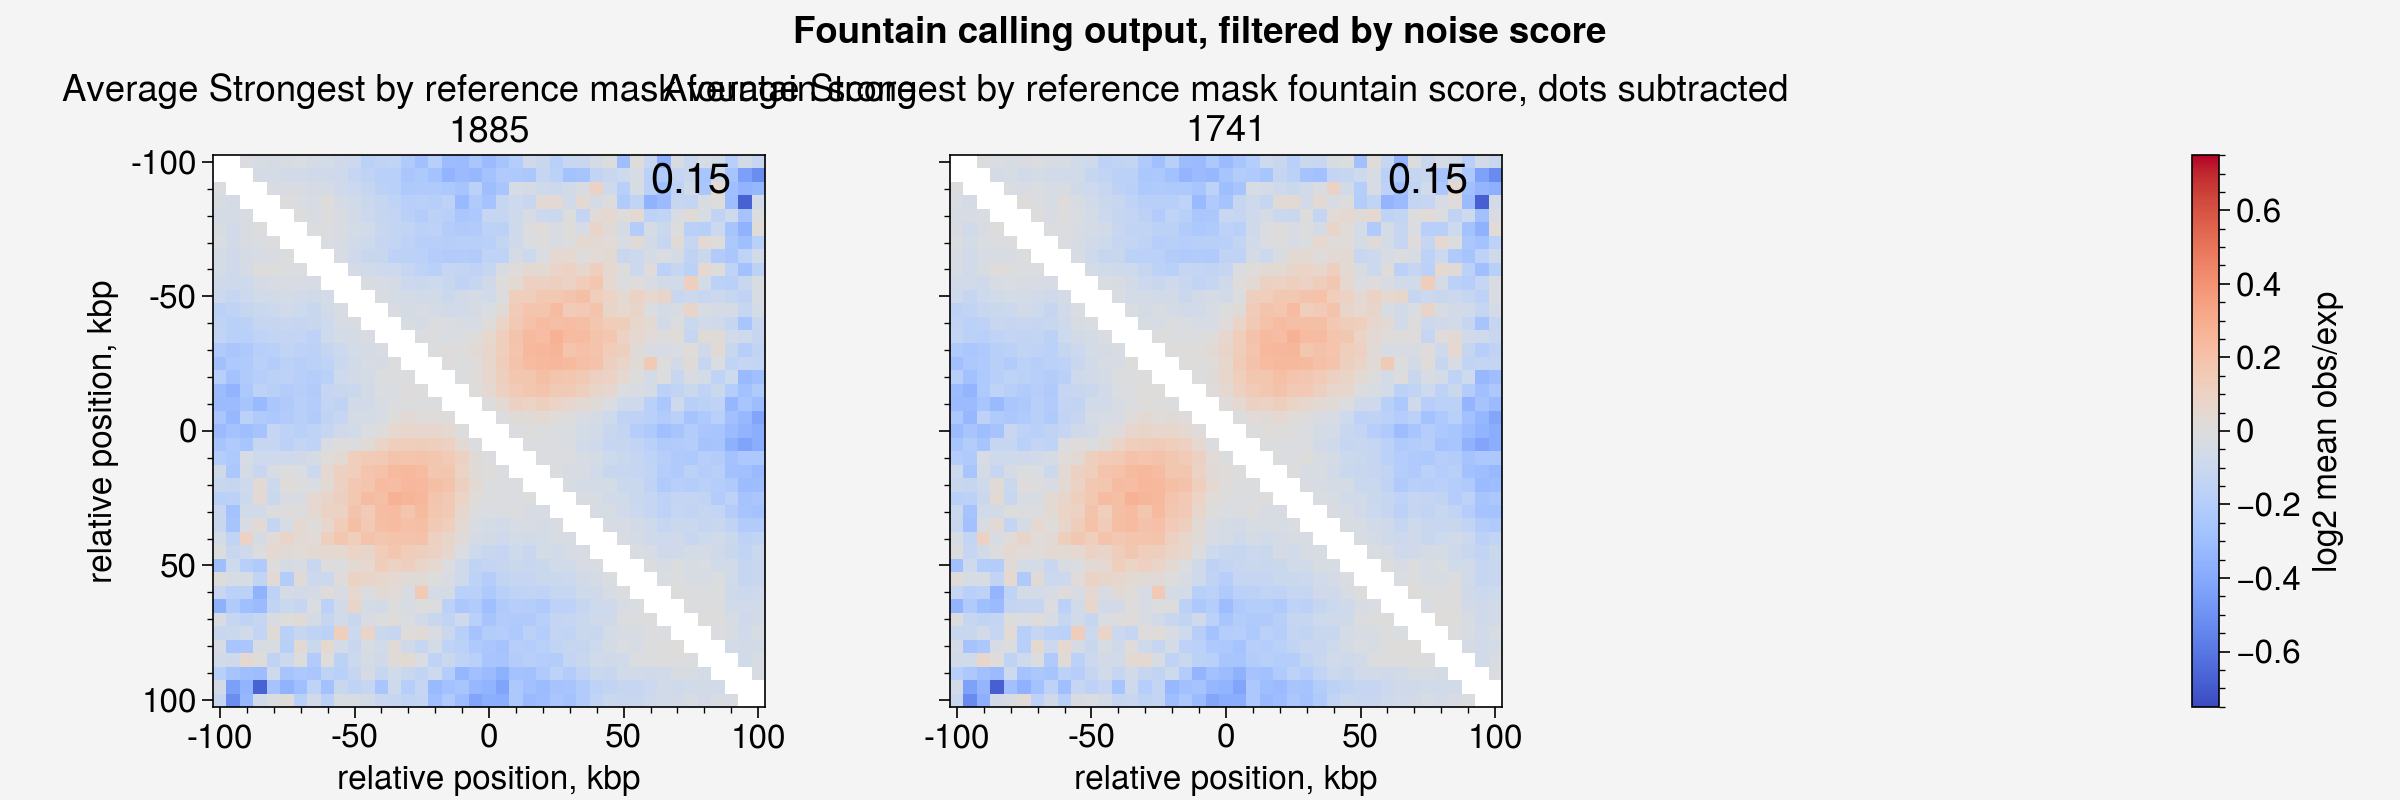

In [29]:
# Plot average patterns:
FLANK = 100_000

fig, axes = plt.subplots(1, 3, figsize=[12, 4], sharey=True, sharex=True)
axes.flatten()[-1].set_axis_off()

for i, (df, title) in enumerate(
    [
        (df_strongest, "Strongest by reference mask fountain score"),
        (
            df_strongest_nodots,
            "Strongest by reference mask fountain score, dots subtracted",
        ),
    ]
):

    bins_fountains = (
        bioframe.overlap(bins, df, how="left", return_index=True)
        .dropna(subset=["chrom_"])
        .set_index("index")
    )
    index_fountains = list(bins_fountains.index.values)

    # Visualize fountain average:
    pile = np.nanmean(stack[:, :, index_fountains], axis=2)
    pile = fontanka.reflect(pile)

    ax = axes.flatten()[i]
    im = ax.imshow(
        np.log2(pile), vmax=0.75, vmin=-0.75, cmap="coolwarm", interpolation=None
    )

    ticks_pixels = np.linspace(0, FLANK * 2 // RESOLUTION, 5)
    ticks_kbp = ((ticks_pixels - ticks_pixels[-1] / 2) * RESOLUTION // 1000).astype(int)
    ax.set_xticks(ticks_pixels)
    ax.set_xticklabels(ticks_kbp)
    ax.set_xlabel("relative position, kbp")

    if i == 0:
        ax.set_yticks(ticks_pixels)
        ax.set_yticklabels(ticks_kbp)
        ax.set_ylabel("relative position, kbp")

    score = np.nanmean(df_fountains.loc[index_fountains, "FS"])
    ax.text(
        32.0,
        0.0,
        f"{score:.2f}",
        horizontalalignment="left",
        verticalalignment="top",
        fontsize=15,
    )

    ax.set_title(f"Average {title}\n{len(index_fountains)}")

plt.colorbar(im, ax=axes.flatten()[-1], label="log2 mean obs/exp")
plt.suptitle("Fountain calling output, filtered by noise score")
plt.tight_layout()

In [30]:
# Examples of fountain hairpins analysis:
df = df_strongest_nodots.copy()

bins_fountains = (
    bioframe.overlap(bins, df, how="left", return_index=True)
    .dropna(subset=["chrom_"])
    .set_index("index")
)
index_fountains = list(bins_fountains.sort_values("FS_", ascending=False).index.values)

idx_selected = index_fountains[:100]
nrows = len(idx_selected) // 10  # n_samples_show
ncols = 10

fig, axes = plt.subplots(nrows, ncols, figsize=[4 * ncols, 4 * nrows])

for i, idx in enumerate(idx_selected):

    ax = axes.flatten()[i]

    mtx = stack[:, :, idx]
    mtx = fontanka.reflect(mtx)

    img = ax.matshow(
        np.log2(mtx), vmin=-1.75, vmax=1.75, cmap="coolwarm", interpolation=None
    )
    ax.xaxis.tick_bottom()
    if i > 0:
        ax.yaxis.set_visible(False)

    ax.xaxis.set_visible(False)

    ax.minorticks_off()
    reg = bins.loc[idx, ["chrom", "start", "end"]]
    ax.set_title(f"{idx}\n{reg.chrom}:{reg.start}-{reg.end}")

    ticks_pixels = np.linspace(0, FLANK * 2 // RESOLUTION, 5)
    ticks_kbp = ((ticks_pixels - ticks_pixels[-1] / 2) * RESOLUTION // 1000).astype(int)
    ax.set_xticks(ticks_pixels)
    ax.set_xticklabels(ticks_kbp)
    ax.set_yticks(ticks_pixels)
    ax.set_yticklabels(ticks_kbp)
    ax.set_xlabel("relative position, kbp")
    ax.set_ylabel("relative position, kbp")

fig.show();